In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os


### Datasets

In [2]:
corrs = load('res_data/correlations.joblib')

In [18]:
import tables, pandas as pd, pathlib
tables.file._open_files.close_all()
p = pathlib.Path(r"res_data/elasticnet_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
with pd.HDFStore(str(p), mode="r") as store:
    print(store.keys())


exists: True size: 175217074 bytes
['/A2M', '/AAAS', '/AACS', '/AAGAB', '/AAK1', '/AAMDC', '/AAMP', '/AAR2', '/AARS', '/AARS2', '/AARSD1', '/AASDHPPT', '/AASS', '/AATF', '/ABCB10', '/ABCB6', '/ABCB7', '/ABCB8', '/ABCC1', '/ABCC4', '/ABCD1', '/ABCD3', '/ABCE1', '/ABCF1', '/ABCF2', '/ABCF3', '/ABHD10', '/ABHD11', '/ABHD12', '/ABHD14B', '/ABHD16A', '/ABI1', '/ABI2', '/ABLIM1', '/ABT1', '/ACAA1', '/ACAA2', '/ACACA', '/ACAD10', '/ACAD8', '/ACAD9', '/ACADM', '/ACADS', '/ACADSB', '/ACADVL', '/ACAP2', '/ACAT1', '/ACAT2', '/ACBD3', '/ACBD5', '/ACBD6', '/ACIN1', '/ACLY', '/ACO1', '/ACO2', '/ACOT13', '/ACOT2', '/ACOT7', '/ACOT8', '/ACOT9', '/ACOX1', '/ACP1', '/ACP2', '/ACP6', '/ACSF2', '/ACSF3', '/ACSL1', '/ACSL3', '/ACSL4', '/ACSL5', '/ACSS2', '/ACTA2', '/ACTB', '/ACTL6A', '/ACTL8', '/ACTN1', '/ACTN4', '/ACTR10', '/ACTR1A', '/ACTR2', '/ACTR3', '/ACTR5', '/ACY1', '/ACYP1', '/ACYP2', '/ADA', '/ADAM10', '/ADAM15', '/ADAM17', '/ADAM9', '/ADAR', '/ADCK3', '/ADCK4', '/ADD1', '/ADD3', '/ADH5', '/ADI1',

In [19]:
A2M = pd.read_hdf('res_data/elasticnet_results.h5', key='A2M')  # replace '/df1' with actual key


In [20]:
A2M

,protein,LOO sample,true,predicted,params_dict
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
...,...,...,...,...,...
364,A2M,FADU_UPPER_AERODIGESTIVE_TRACT,-1.116991,-0.698824,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
365,A2M,KP4_PANCREAS,1.922976,-0.334505,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"
366,A2M,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-1.106344,-0.849375,"{""alpha"": 0.1, ""l1_ratio"": 0.9}"
367,A2M,OVCAR8_OVARY,-0.770372,0.063654,"{""alpha"": 0.5, ""l1_ratio"": 0.5}"


In [21]:
# Load all data from the HDF5 file
h5_file = 'res_data/elasticnet_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)

combined_df.head()


,protein,LOO sample,true,predicted,params_dict,abs_error,squared_error,rel_error
0,A2M,MDAMB468_BREAST,-0.345562,-0.276651,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.068912,4.748821e-03,0.199419
1,A2M,SH4_SKIN,1.642186,0.308402,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.333784,1.778980e+00,0.812200
2,A2M,AU565_BREAST,-1.129114,-0.899868,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.229246,5.255372e-02,0.203032
3,A2M,KMRC1_KIDNEY,1.493333,-0.222243,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",1.715576,2.943201e+00,1.148823
4,A2M,CAL51_BREAST,0.274652,0.275565,"{""alpha"": 0.5, ""l1_ratio"": 0.5}",0.000913,8.334106e-07,0.003324


##  Protein-wise analysis


### Statistics on errors 

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


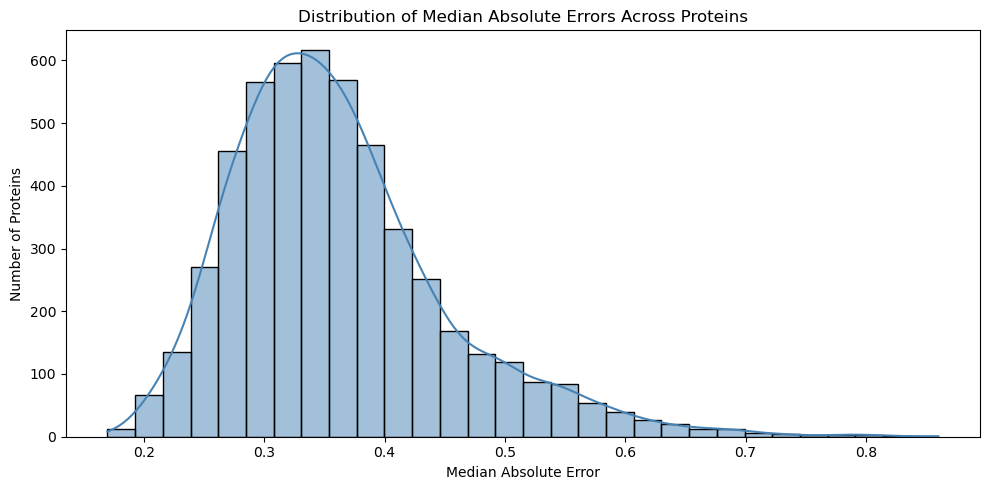

In [22]:

# 1. Compute median absolute error for each protein across samples
protein_medians = combined_df.groupby("protein")["abs_error"].median().reset_index()
protein_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# 2. Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians["median_abs_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Median Absolute Errors Across Proteins")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


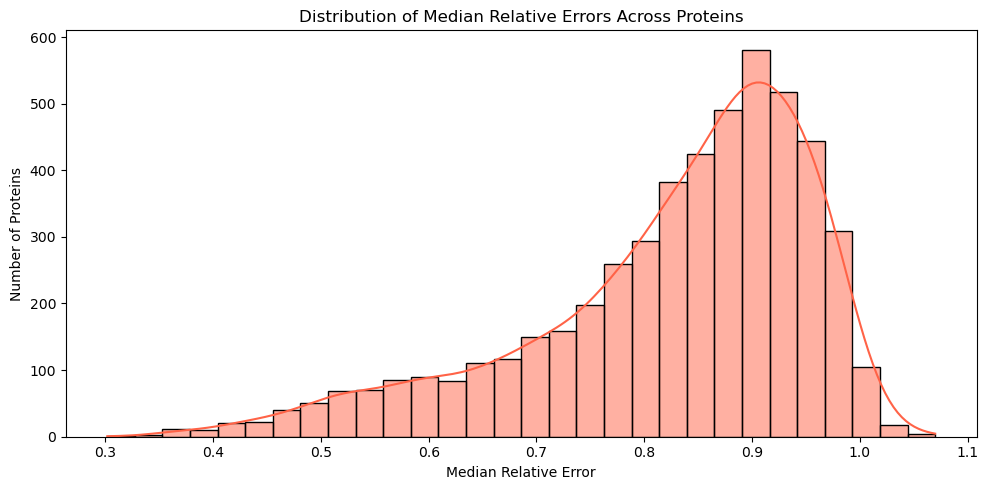

In [23]:
# Compute median relative error across all samples per protein
protein_medians_rel = combined_df.groupby("protein")["rel_error"].median().reset_index()
protein_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians_rel["median_rel_error"], bins=30, kde=True, color="tomato")

plt.title("Distribution of Median Relative Errors Across Proteins")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()


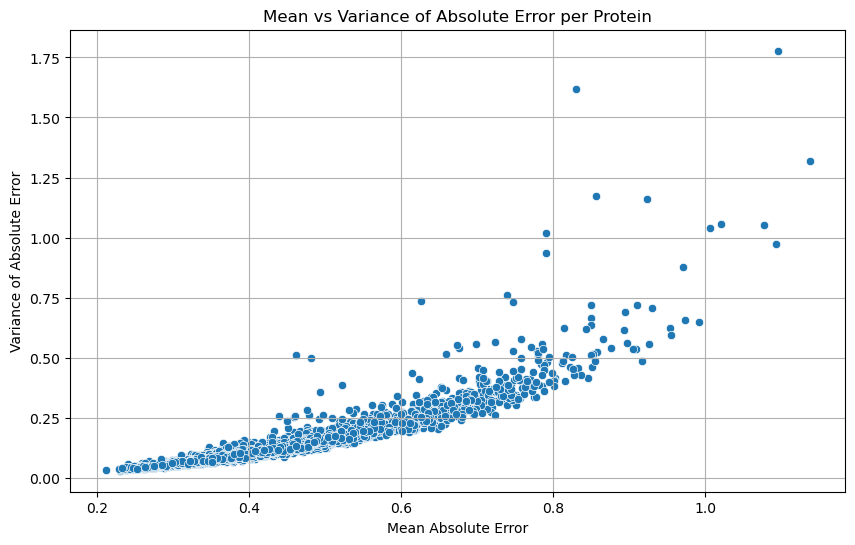

In [24]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

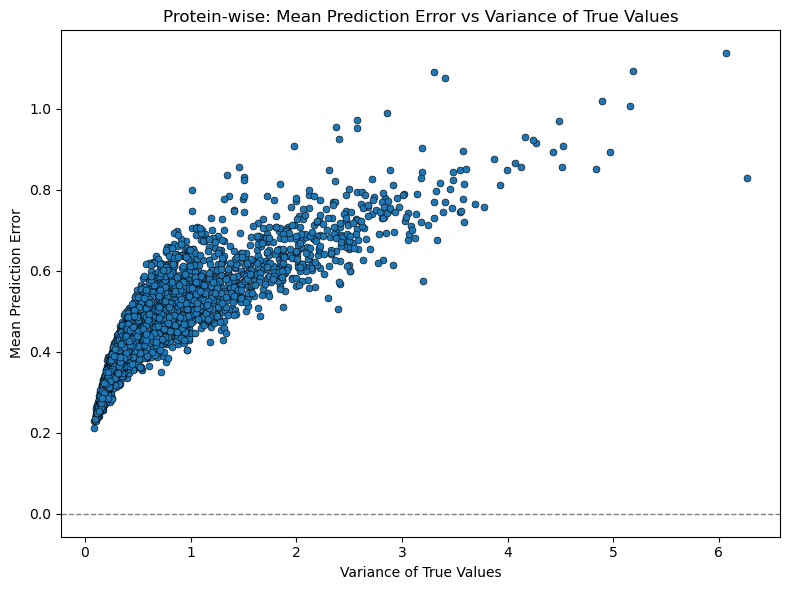

In [25]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Best proteins and Samples analysis


In [26]:
protein_error_summary = combined_df.groupby('protein').agg(
    median_abs_error=('abs_error', 'median'),
    std_abs_error=('abs_error', 'std'),
    median_squared_error=('squared_error', 'median'),
    std_squared_error=('squared_error', 'std'),
    #count=('protein', 'count')
    median_rel_error=('rel_error', 'median'),
    std_rel_error=('rel_error', 'std')
).sort_values(by='median_abs_error', ascending=True)

protein_error_summary.head(10)


,median_abs_error,std_abs_error,median_squared_error,std_squared_error,median_rel_error,std_rel_error
protein,,,,,,
PSMC6,0.169596,0.191837,0.028763,0.136640,0.938223,2.645553
PPP1CC,0.169774,0.176472,0.028823,0.136845,0.940759,11.219178
DYNLL1,0.174422,0.239938,0.030423,0.319245,0.969939,14.855984
PTBP3,0.185625,0.188581,0.034456,0.145528,0.852404,6.779830
POLR2B,0.186612,0.218718,0.034824,0.182846,0.958891,40.912805
PSMC1,0.186671,0.180773,0.034846,0.132758,0.929492,38.670090
PPP1CB,0.188081,0.219388,0.035375,0.194042,0.877395,6.140146
RPL11,0.189306,0.217769,0.035837,0.193687,0.932926,4.307486
PSMC4,0.189509,0.196623,0.035914,0.154007,0.973372,4.763272


In [27]:
protein_name = 'DYNLL1'
# Filter combined_df for that protein
protein_df = combined_df[combined_df['protein'] == protein_name]
# Sort SAMPLES by absolute error
protein_df_sorted = protein_df.sort_values(by='abs_error', ascending=True)
# Display
smallest_error = protein_df_sorted[protein_df_sorted["abs_error"]< 0.1]
smallest_error[['LOO sample', 'abs_error']]  

,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


display the samples with less than 0.1 error

In [28]:
def get_less_than01(protein_name, df, error_col='abs_error', sample_col='LOO sample'):
    protein_df = df[df['protein'] == protein_name]
    sorted_df = protein_df.sort_values(by=error_col, ascending=True)
    return sorted_df[[sample_col, error_col]].query(f"{error_col} < 0.1")

small = get_less_than01('DYNLL1', combined_df)
small


,LOO sample,abs_error
465082,HCC2218_BREAST,0.000168
465029,A549_LUNG,0.001852
464987,BT549_BREAST,0.001941
465174,KYM1_SOFT_TISSUE,0.003911
465273,UMUC3_URINARY_TRACT,0.003959
...,...,...
465150,HEC6_ENDOMETRIUM,0.093950
464953,KMRC20_KIDNEY,0.094580
465066,LOXIMVI_SKIN,0.096903
465023,LK2_LUNG,0.097010


In [29]:


# Extract the tissue type from the LOO sample
small['tissue'] = small['LOO sample'].str.extract(r'_([A-Z]+)$')

# Count the occurrences of each tissue
tissue_counts = small['tissue'].value_counts()

print(tissue_counts)


tissue
LUNG           20
SKIN           16
INTESTINE      11
LIVER           9
BREAST          8
TRACT           7
OESOPHAGUS      6
SYSTEM          6
ENDOMETRIUM     5
OVARY           5
STOMACH         5
TISSUE          4
KIDNEY          4
PANCREAS        3
PROSTATE        2
PLEURA          2
BONE            1
THYROID         1
Name: count, dtype: int64


Check between the best proteins for absolute error if the samples correspond

In [30]:
# Get the top 10 proteins with the lowest median absolute error
top_10_proteins = protein_error_summary.head(10).index.tolist()

# Dictionary to store results
low_error_samples_by_protein = {}

# Loop through top 10 proteins and apply your function
for prot in top_10_proteins:
    low_error_samples_by_protein[prot] = get_less_than01(prot, combined_df)

# see low-error samples for the first protein
low_error_samples_by_protein[top_10_proteins[0]]
summary = {
    prot: len(df)
    for prot, df in low_error_samples_by_protein.items()
}

summary_df = pd.DataFrame.from_dict(summary, orient='index', columns=['low_error_count'])
summary_df


,low_error_count
PSMC6,115
PPP1CC,116
DYNLL1,115
PTBP3,106
POLR2B,114
PSMC1,94
PPP1CB,100
RPL11,109
PSMC4,104
PUM1,108


In [31]:
low_error_sample_sets = {
    prot: set(get_less_than01(prot, combined_df)['LOO sample'])
    for prot in top_10_proteins
}

# Find intersection: samples that are low-error across *all* top 10 proteins
common_low_error_samples = set.union(*low_error_sample_sets.values())

print(f"Number of samples with abs_error < 0.1 across ALL top 10 proteins: {len(common_low_error_samples)}")
print("Common samples:", common_low_error_samples)

Number of samples with abs_error < 0.1 across ALL top 10 proteins: 353
Common samples: {'WM2664_SKIN', 'SNGM_ENDOMETRIUM', 'NCIH2122_LUNG', 'HS294T_SKIN', 'HT115_LARGE_INTESTINE', '769P_KIDNEY', 'MCF7_BREAST', 'CAL120_BREAST', 'MELJUSO_SKIN', 'HDQP1_BREAST', 'G401_SOFT_TISSUE', 'PC14_LUNG', 'MDAMB436_BREAST', 'KYSE30_OESOPHAGUS', 'PANC0403_PANCREAS', 'JHH1_LIVER', 'JM1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'DAOY_CENTRAL_NERVOUS_SYSTEM', '697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'WM793_SKIN', 'NCIH2030_LUNG', 'MSTO211H_PLEURA', 'JHH7_LIVER', 'NCIH441_LUNG', 'EBC1_LUNG', 'HCC56_LARGE_INTESTINE', 'SW1573_LUNG', 'U2OS_BONE', 'SNU449_LIVER', 'THP1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'LN229_CENTRAL_NERVOUS_SYSTEM', 'HEC6_ENDOMETRIUM', 'CHAGOK1_LUNG', 'REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'HCC1937_BREAST', 'CAMA1_BREAST', 'A673_BONE', 'NCIH2228_LUNG', 'J82_URINARY_TRACT', 'LU65_LUNG', 'CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE', 'SKES1_BONE', 'ABC1_LUNG', 'NCIH1975_LUNG', 'C32_SKIN', 'L33_P

How many times a tissue appears in the top predicted proteins

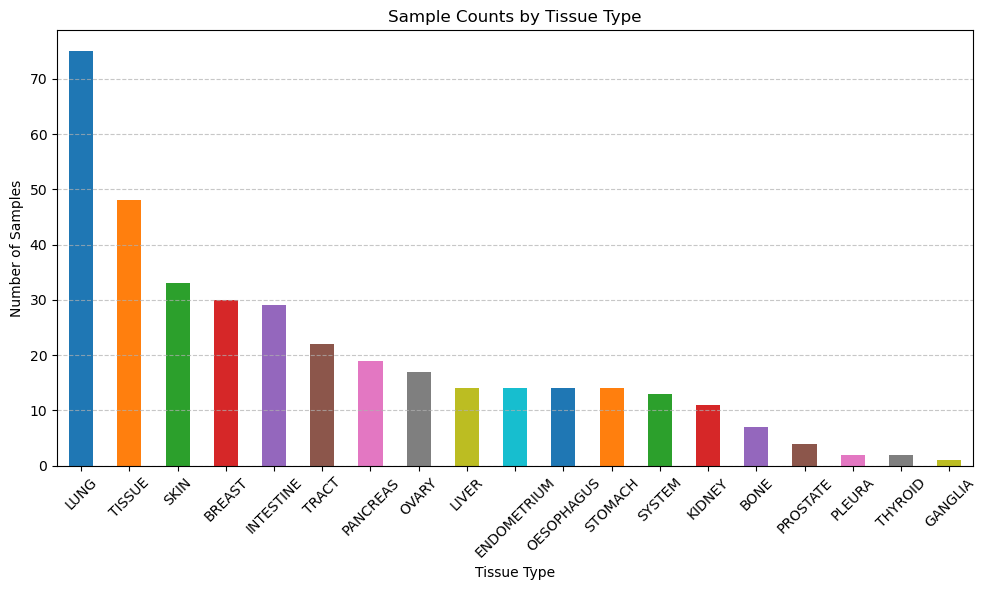

In [32]:
protein_df_sorted['tissue'] = protein_df_sorted['LOO sample'].str.extract(r'_([A-Z]+)$')

# Count occurrences of each tissue type
tissue_counts = protein_df_sorted['tissue'].value_counts()

# Assign a different color to each tissue
colors = plt.cm.tab10.colors  # Use a colormap with distinct colors
color_list = colors[:len(tissue_counts)]  # Adjust if >10 tissues

# Plot with different colors
plt.figure(figsize=(10, 6))
tissue_counts.plot(kind='bar', color=color_list)
plt.title('Sample Counts by Tissue Type')
plt.xlabel('Tissue Type')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [33]:
# Convert the union of sets to a list before using it as index
all_samples = list(set.union(*low_error_sample_sets.values()))

# Create the sample matrix with proper indexing
sample_matrix = pd.DataFrame(index=all_samples)

# Populate the matrix with binary indicators
for prot, sample_set in low_error_sample_sets.items():
    sample_matrix[prot] = sample_matrix.index.isin(sample_set).astype(int)

# Count in how many proteins each sample appears
sample_matrix['num_proteins'] = sample_matrix.sum(axis=1)

# Sort to find the most consistent low-error samples
sample_matrix_sorted = sample_matrix.sort_values(by='num_proteins', ascending=False)

# Step 1: Reset index to get sample names as a column
sample_matrix_reset = sample_matrix_sorted.reset_index().rename(columns={'index': 'sample'})

# Step 2: Extract tissue type from sample names (split by last underscore)
sample_matrix_reset['tissue'] = sample_matrix_reset['sample'].apply(lambda x: x.split('_')[-1])

# Step 3: Group by tissue and sum across all protein columns
tissue_summary = sample_matrix_reset.groupby('tissue').sum(numeric_only=True)

# Optional: Sort by number of appearances across proteins
tissue_summary = tissue_summary.sort_values(by='num_proteins', ascending=False)

tissue_summary.head(10)


,PSMC6,PPP1CC,DYNLL1,PTBP3,POLR2B,PSMC1,PPP1CB,RPL11,PSMC4,PUM1,num_proteins
tissue,,,,,,,,,,,
LUNG,19,27,20,24,20,23,24,24,15,24,220
BREAST,13,13,8,7,13,8,15,13,8,11,109
SKIN,9,10,16,8,11,10,11,8,13,9,105
TISSUE,15,11,4,5,12,10,10,12,10,5,94
INTESTINE,9,15,11,9,5,5,9,5,11,10,89
PANCREAS,11,5,3,9,6,5,6,9,7,4,65
TRACT,1,9,7,4,7,6,2,5,5,9,55
LIVER,7,5,9,5,5,4,2,5,4,6,52
OVARY,4,6,5,4,7,2,3,5,9,5,50


### MAE vs correlations

In [34]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


In [35]:
sorted(protein_error_summary.index)

['A2M',
 'AAAS',
 'AACS',
 'AAGAB',
 'AAK1',
 'AAMDC',
 'AAMP',
 'AAR2',
 'AARS',
 'AARS2',
 'AARSD1',
 'AASDHPPT',
 'AASS',
 'AATF',
 'ABCB10',
 'ABCB6',
 'ABCB7',
 'ABCB8',
 'ABCC1',
 'ABCC4',
 'ABCD1',
 'ABCD3',
 'ABCE1',
 'ABCF1',
 'ABCF2',
 'ABCF3',
 'ABHD10',
 'ABHD11',
 'ABHD12',
 'ABHD14B',
 'ABHD16A',
 'ABI1',
 'ABI2',
 'ABLIM1',
 'ABT1',
 'ACAA1',
 'ACAA2',
 'ACACA',
 'ACAD10',
 'ACAD8',
 'ACAD9',
 'ACADM',
 'ACADS',
 'ACADSB',
 'ACADVL',
 'ACAP2',
 'ACAT1',
 'ACAT2',
 'ACBD3',
 'ACBD5',
 'ACBD6',
 'ACIN1',
 'ACLY',
 'ACO1',
 'ACO2',
 'ACOT13',
 'ACOT2',
 'ACOT7',
 'ACOT8',
 'ACOT9',
 'ACOX1',
 'ACP1',
 'ACP2',
 'ACP6',
 'ACSF2',
 'ACSF3',
 'ACSL1',
 'ACSL3',
 'ACSL4',
 'ACSL5',
 'ACSS2',
 'ACTA2',
 'ACTB',
 'ACTL6A',
 'ACTL8',
 'ACTN1',
 'ACTN4',
 'ACTR10',
 'ACTR1A',
 'ACTR2',
 'ACTR3',
 'ACTR5',
 'ACY1',
 'ACYP1',
 'ACYP2',
 'ADA',
 'ADAM10',
 'ADAM15',
 'ADAM17',
 'ADAM9',
 'ADAR',
 'ADCK3',
 'ADCK4',
 'ADD1',
 'ADD3',
 'ADH5',
 'ADI1',
 'ADIRF',
 'ADK',
 'ADNP',
 'ADO',


In [51]:
corrs = corrs.reindex(protein_error_summary.index)
corrs

,pearson,spearman,kendall
protein,,,
PSMC6,0.115772,0.175161,0.119969
PPP1CC,0.060099,0.088507,0.060123
DYNLL1,0.380480,0.321732,0.221931
PTBP3,0.384710,0.419539,0.284961
POLR2B,0.197530,0.181712,0.125360
...,...,...,...
CDKN2A,0.551237,0.575559,0.399110
TP53,0.594785,0.604229,0.429064
SLC1A3,0.655389,0.613826,0.435744


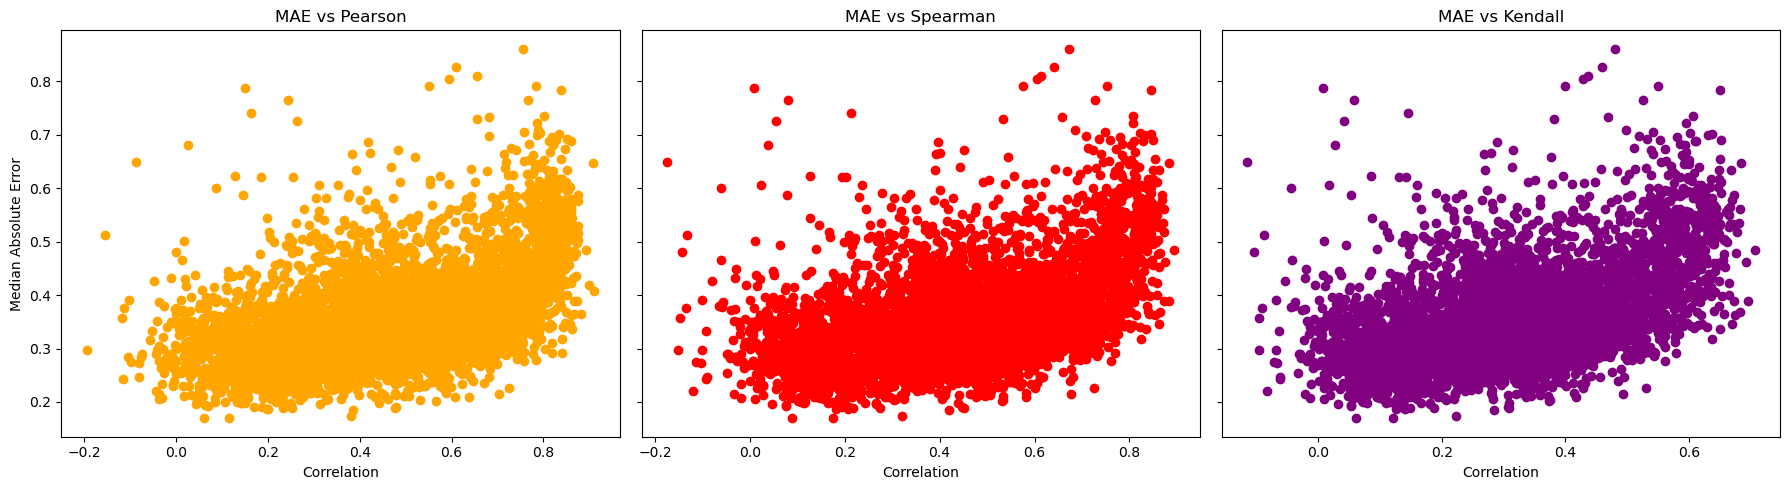

In [52]:

mae = protein_error_summary['median_abs_error']

# Define custom colors for each correlation type
colors = ['orange', 'red', 'purple']  # Feel free to change these

# Create subplots: 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Plot each correlation type separately
for ax, col, color in zip(axes, corrs.columns, colors):
    ax.scatter(corrs[col], mae, color=color)
    ax.set_title(f'MAE vs {col.capitalize()}')
    ax.set_xlabel('Correlation')
    ax.grid(False)

# Common Y label
axes[0].set_ylabel('Median Absolute Error')

plt.tight_layout()
plt.show()



## Samples

In [38]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.920625,0.610738,1.220479,1.455291,5113
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.767843,0.582728,0.929088,1.412112,5113
KNS81_CENTRAL_NERVOUS_SYSTEM,0.722669,0.540907,0.814773,1.251792,5113
NCIH1573_LUNG,0.699855,0.581263,0.827597,1.407798,5113
IM95_STOMACH,0.698584,0.537699,0.777084,2.054422,5113


c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


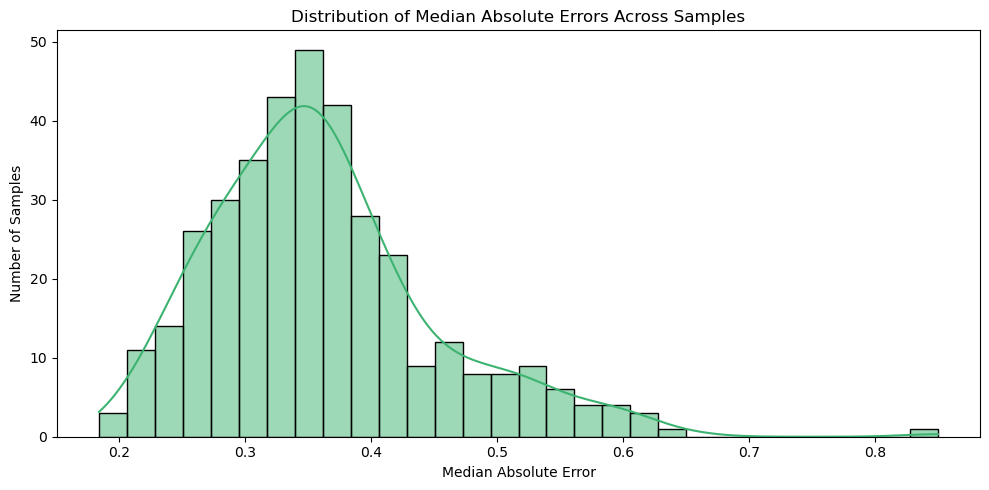

In [39]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["abs_error"].median().reset_index()
sample_medians.rename(columns={"abs_error": "median_abs_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_abs_error"], bins=30, kde=True, color="mediumseagreen")

plt.title("Distribution of Median Absolute Errors Across Samples")
plt.xlabel("Median Absolute Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


c:\Users\ccald\anaconda3\envs\thesis_env\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


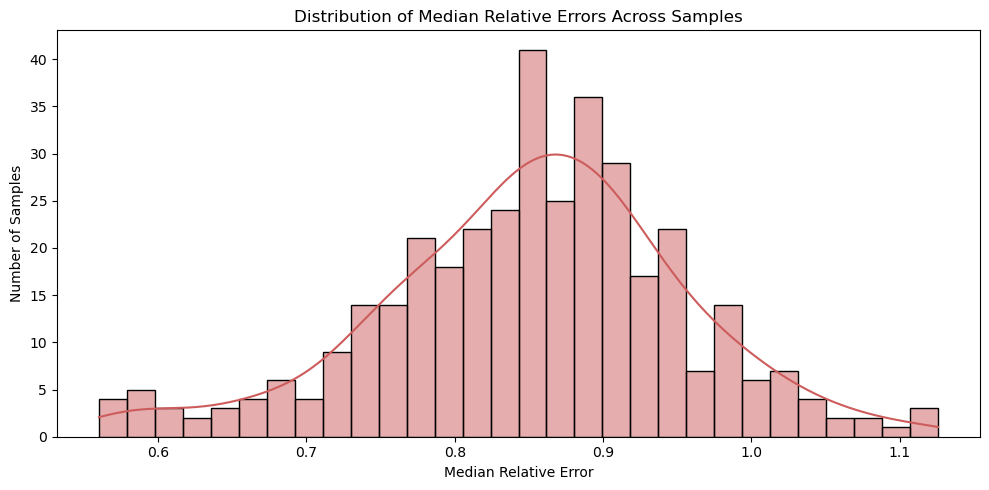

In [40]:
# Compute median relative error across proteins for each sample
sample_medians_rel = combined_df.groupby("LOO sample")["rel_error"].median().reset_index()
sample_medians_rel.rename(columns={"rel_error": "median_rel_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians_rel["median_rel_error"], bins=30, kde=True, color="indianred")

plt.title("Distribution of Median Relative Errors Across Samples")
plt.xlabel("Median Relative Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


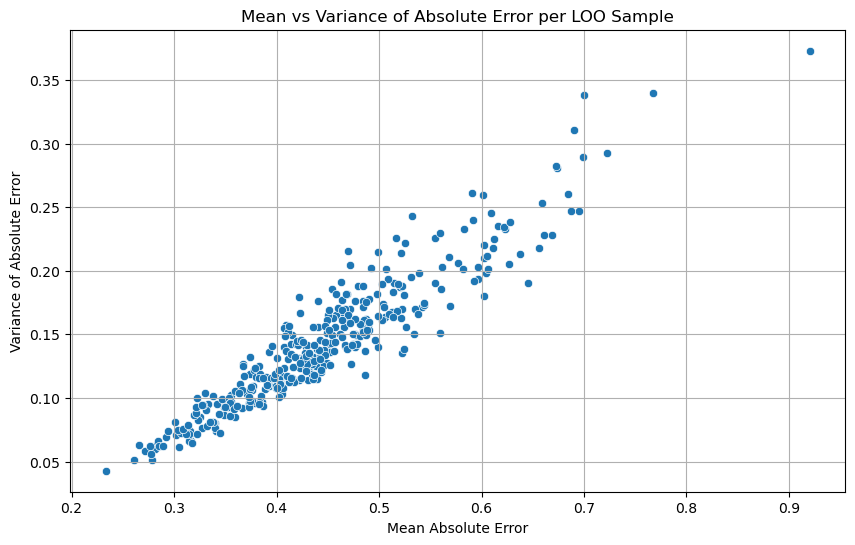

In [41]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


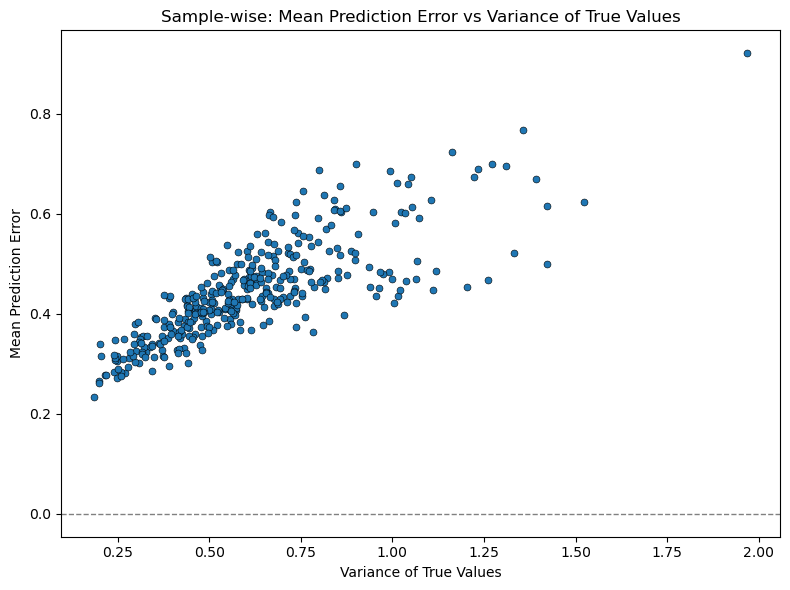

In [42]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

## Cluster-Wise analysis

In [43]:
clusters = pd.read_csv("res_data/protein_clusters_k3.csv")

In [44]:
clusters

,Protein,Cluster
0,A2M,3
1,AAAS,3
2,AACS,3
3,AAGAB,1
4,AAK1,2
...,...,...
5108,ZRANB2,1
5109,ZW10,3
5110,ZWILCH,1
5111,ZYX,3


Distributions

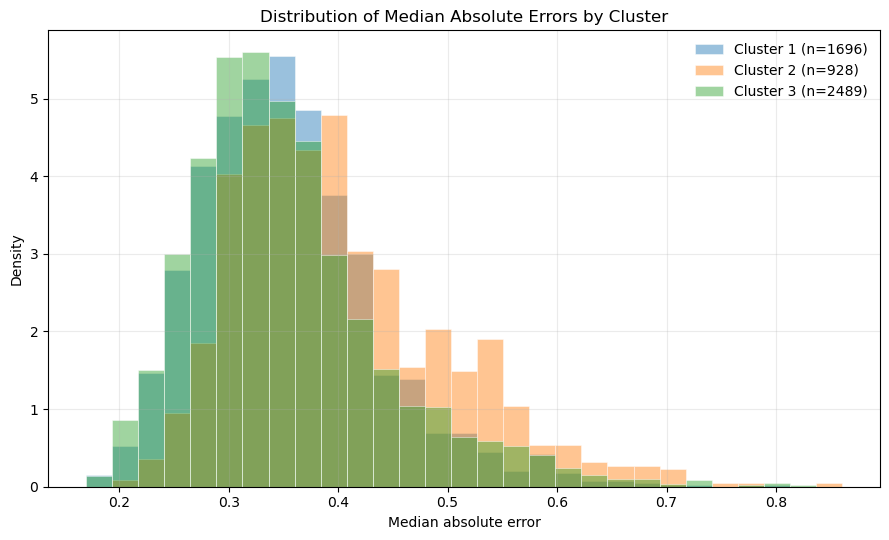

In [45]:

# --- Prep: merge error + cluster labels ---
err = protein_error_summary[['median_abs_error']].rename_axis('Protein').reset_index()
df = err.merge(clusters, on='Protein', how='inner')

# Consistent bins across clusters
bins = np.linspace(df['median_abs_error'].min(), df['median_abs_error'].max(), 30)

# Pick distinct colors for the three clusters
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # blue, orange, green

plt.figure(figsize=(9, 5.5))
for c in sorted(df['Cluster'].unique()):
    vals = df.loc[df['Cluster'] == c, 'median_abs_error']
    plt.hist(
        vals, bins=bins, density=True, alpha=0.45,
        label=f"Cluster {c} (n={len(vals)})",
        color=palette.get(c, None), edgecolor="white", linewidth=0.7
    )

plt.title("Distribution of Median Absolute Errors by Cluster")
plt.xlabel("Median absolute error")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


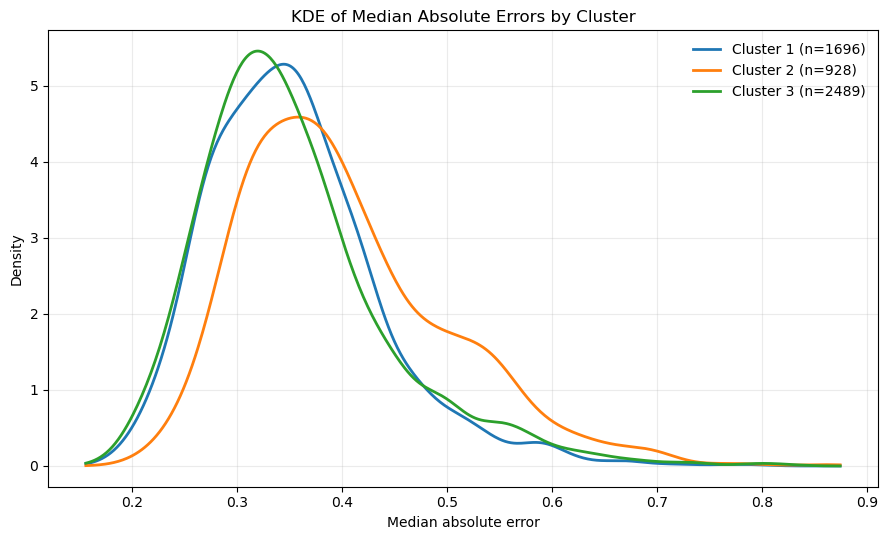

In [46]:

from scipy.stats import gaussian_kde

# err + clusters already merged into df as in your snippet
# df has columns: Protein, median_abs_error, Cluster
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}

# Common x-axis over the full range (with a small padding)
xmin, xmax = df['median_abs_error'].min(), df['median_abs_error'].max()
xr = np.linspace(xmin - 0.02*(xmax - xmin), xmax + 0.02*(xmax - xmin), 512)

plt.figure(figsize=(9, 5.5))
for c in sorted(df['Cluster'].unique()):
    vals = df.loc[df['Cluster'] == c, 'median_abs_error'].to_numpy()

    if len(vals) < 2:
        # KDE needs >=2 points; fall back to a thin vertical line at the value
        if len(vals) == 1:
            plt.axvline(vals[0], ymax=0.12, color=palette[c], lw=2, label=f"Cluster {c} (n=1)")
        continue

    kde = gaussian_kde(vals)  # you can tune bandwidth via bw_method=0.3, etc.
    y = kde(xr)
    plt.plot(xr, y, lw=2, color=palette[c], label=f"Cluster {c} (n={len(vals)})")
    # Optional soft shading (comment out if you truly want lines only)
    # plt.fill_between(xr, y, alpha=0.12, color=palette[c])

plt.title("KDE of Median Absolute Errors by Cluster")
plt.xlabel("Median absolute error")
plt.ylabel("Density")
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Scatterplot

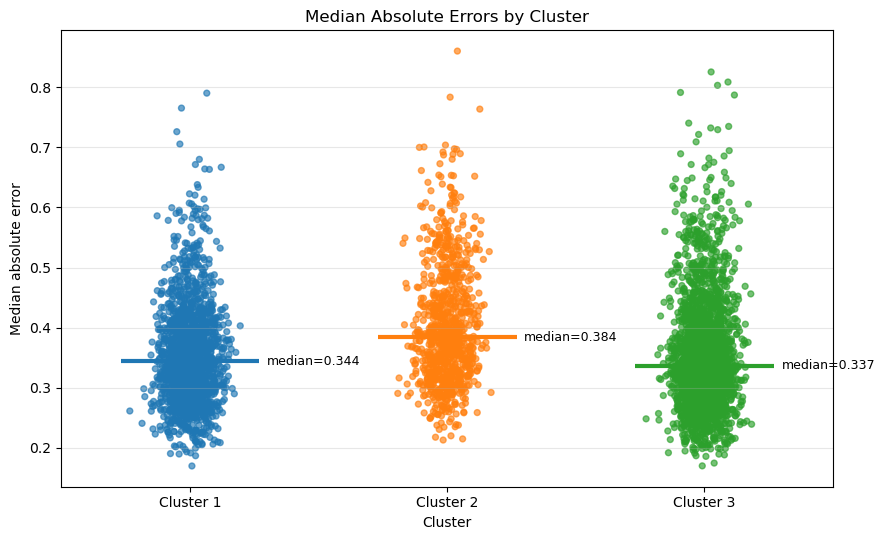

In [47]:

rng = np.random.default_rng(0)  # reproducible jitter
x = df['Cluster'].astype(int).to_numpy()
y = df['median_abs_error'].to_numpy()

# Small horizontal jitter so points don’t overlap
x_jittered = x + rng.normal(0, 0.06, size=len(x))
colors = df['Cluster'].map(palette).to_numpy()

plt.figure(figsize=(9, 5.5))
plt.scatter(x_jittered, y, s=18, alpha=0.65, c=colors)

# Add one horizontal median line per cluster for visual comparison
for c in sorted(df['Cluster'].unique()):
    y_c = df.loc[df['Cluster'] == c, 'median_abs_error']
    plt.hlines(y_c.median(), c - 0.27, c + 0.27, colors=palette[c], linewidth=3)
    plt.text(c + 0.3, y_c.median(), f"median={y_c.median():.3f}", fontsize=9, va="center")

plt.xticks([1, 2, 3], ["Cluster 1", "Cluster 2", "Cluster 3"])
plt.xlim(0.5, 3.5)
plt.title("Median Absolute Errors by Cluster") #scattered by jitter
plt.xlabel("Cluster")
plt.ylabel("Median absolute error")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
